# 07e — Causal Example (DML)

In [1]:
# Cell 1 — setup
import sys, pathlib
sys.path.append(str(pathlib.Path.cwd().parent / "src"))
from scorelab import config, data
con = data.connect()            # read-only DuckDB connection to data/lc.duckdb

In [2]:
# Cell 2 — sanity check
print(con.sql("SHOW TABLES"))
print(con.sql("SELECT COUNT(*) AS n, MIN(issue_d), MAX(issue_d) FROM accepted"))

┌─────────────────┐
│      name       │
│     varchar     │
├─────────────────┤
│ accepted        │
│ rejected        │
│ v_accepted_asof │
│ v_split         │
│ v_target        │
└─────────────────┘

┌─────────┬──────────────┬──────────────┐
│    n    │ min(issue_d) │ max(issue_d) │
│  int64  │     date     │     date     │
├─────────┼──────────────┼──────────────┤
│ 2260668 │ 2007-06-01   │ 2018-12-01   │
└─────────┴──────────────┴──────────────┘



In [3]:
# Cell 3 — common imports and settings for this notebook
import json, warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 200)
from scorelab import target, attributes as A, binning as B, scorecard as S, validation as V, fairness as F
from scorelab import challengers as C, reject_inference as R, monitoring as M, report as REP
from scorelab import tuning as T, explain as E, survival as SV, causal as CA
MODELS = config.MODELS_DIR; MODELS.mkdir(exist_ok=True)
SAMPLE_FRAC = None     # None = full data (recommended for the fitting notebooks); e.g. 0.10 for a quick pass
cols = [r[0] for r in con.execute("DESCRIBE v_target").fetchall()]
assert "label" in cols, "v_target is the old stub: close this kernel and run `python scripts/refresh_views.py`"
def load_frame(splits=("train", "validate", "oot"), **kw):
    """Observable, non-excluded loans with attributes built; indeterminates dropped unless asked."""
    f = target.modeling_frame(con, splits=splits, sample_frac=SAMPLE_FRAC, **kw)
    return A.build_attributes(f)
MEANINGS = {a.name: a.meaning for a in A.REGISTRY}
DIRECTIONS = {a.name: a.direction for a in A.REGISTRY}

## What this notebook settles

A short, **illustrative** causal estimate: the difference in the probability of going bad within 24 months between a 60-month and a 36-month term, for applicants with the same application attributes, by double machine learning (cross-fitted partially linear model, and the doubly robust interactive model for the ATE and ATT).

**This is not a causal claim for policy.** The borrower chooses the term and the lender prices it, so the 60-month group differs in ways no application attribute records (payment pressure, purpose, expected income), and the estimate cannot rule that out. Interest rate, grade and instalment are left out of the controls on purpose: the lender sets them after the term is chosen, so controlling for them would remove part of the effect being estimated.

Decision: **AC — the control set, the estimand, and how the number may be used.**

In [4]:
CAUSAL_SAMPLE = 0.25                         # share of 2013-2016 loans (DML fits 3 learners x 5 folds)
cands = json.loads((MODELS / "candidate_attributes.json").read_text(encoding="utf-8"))["candidates"]
cf = A.build_attributes(CA.causal_frame(con, sample_frac=SAMPLE_FRAC or CAUSAL_SAMPLE))
print(f"{len(cf):,} loans · 60-month share {cf.treated.mean():.1%}")
display(cf.groupby(["vintage_year", "term_months"])["bad"].agg(["size", "mean"]).unstack().round(4))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

298,928 loans · 60-month share 28.8%


size           mean        
term_months      36     60      36      60
vintage_year                              
2013          24656   8505  0.0783  0.1208
2014          39966  17733  0.0874  0.1238
2015          69591  33754  0.0992  0.1472
2016          78715  26008  0.1108  0.1506

### Decision AC — Controls and estimand

Controls: the bureau candidates plus application fields (amount, income, DTI, employment length, purpose, home ownership). Is amount a confounder (it drives both term choice and risk) or partly a consequence of the term (a longer term makes a larger amount affordable)? ATE (every applicant) or ATT (applicants who chose 60 months)? What may the number be used for: a sanity check on the size of the term effect in the risk ranking, never a pricing or product decision.

**Your reasoning:**

**DRAFT** (Claude, 2026-11-01, from this notebook's full-data outputs; for review). The notebook ran with the defaults in the code cells; this draft says whether to keep them.

**Keep the controls as listed, with loan amount as a confounder. Report the ATT as the headline and the ATE beside it.**

- **Amount stays in.** Amount drives both the term choice and the risk, so leaving it out would load its risk onto the term. The risk is that amount is partly a consequence of the 60-month term; if so, the estimate is a lower bound on the total association.
- **Why the ATT:** the population that actually chose 60 months is the one the risk ranking has to describe. The ATT is also better supported than the ATE.
- **The overlap evidence:**
  - Among loans with a propensity at or below 0.1, only 435 of 92,859 are 60-month.
  - The interactive model trimmed 88,314 of 298,928 loans (30%).
  - So the ATE leans on extrapolation for 36-month borrowers who would rarely choose 60 months.
- **Permitted use:** a sanity check on the size of the term effect inside the risk ranking. It is never a pricing or product decision.

In [5]:
controls = [c for c in cands if c in cf] + CA.APPLICATION_CONTROLS
X = CA.control_matrix(cf, controls, CA.APPLICATION_CATEGORICALS)
y, d = cf["bad"].to_numpy(), cf["treated"].to_numpy()
bench = CA.naive_and_adjusted(y, d, X)
plr = CA.dml_plr(y, d, X, n_folds=5)
irm = CA.dml_irm(y, d, X, n_folds=5, trim=0.01)
est = pd.concat([bench, pd.DataFrame([
    {"estimator": "DML partially linear (theta)", "effect": plr["theta"], "ci_low": plr["ci"][0], "ci_high": plr["ci"][1]},
    {"estimator": "DML interactive, ATE", "effect": irm["ate"], "ci_low": irm["ate_ci"][0], "ci_high": irm["ate_ci"][1]},
    {"estimator": "DML interactive, ATT", "effect": irm["att"], "ci_low": irm["att_ci"][0], "ci_high": irm["att_ci"][1]}])], ignore_index=True)
display(est.round(4))
print(f"nuisance fits: outcome AUC {plr['outcome_auc']:.3f} · propensity AUC {plr['propensity_auc']:.3f} · trimmed {irm['n_propensity_trimmed']:,} of {irm['n']:,}")
est.to_csv(config.DOCS_DIR / "exhibits" / "dml_term_effect.csv", index=False)

,estimator,effect,ci_low,ci_high
0,raw difference in bad rate,0.0420,NaN,NaN
1,"logistic regression, average marginal effect",0.0294,NaN,NaN
2,DML partially linear (theta),0.0264,0.0234,0.0293
3,"DML interactive, ATE",0.0315,0.0270,0.0360
4,"DML interactive, ATT",0.0262,0.0230,0.0293


nuisance fits: outcome AUC 0.692 · propensity AUC 0.818 · trimmed 88,314 of 298,928


,band,n,treated,control
0,"(-0.001, 0.1]",92859,435,92424
1,"(0.1, 0.2]",19132,2862,16270
2,"(0.2, 0.3]",31707,7864,23843
3,"(0.3, 0.4]",44751,15813,28938
4,"(0.4, 0.5]",46701,21116,25585
5,"(0.5, 0.6]",38003,20872,17131
6,"(0.6, 0.7]",21670,13983,7687
7,"(0.7, 0.8]",4093,3047,1046
8,"(0.8, 0.9]",12,8,4
9,"(0.9, 1.0]",0,0,0


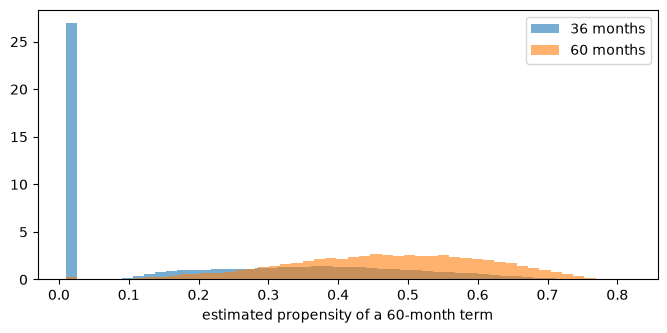

In [6]:
# Evidence — overlap: are there 36- and 60-month borrowers with the same propensity?
ov = CA.overlap_table(irm["propensity"], d); display(ov)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(irm["propensity"][d == 0], bins=50, alpha=0.6, density=True, label="36 months")
ax.hist(irm["propensity"][d == 1], bins=50, alpha=0.6, density=True, label="60 months")
ax.set_xlabel("estimated propensity of a 60-month term"); ax.legend(); plt.show()

In [7]:
# Evidence — is the estimate stable across vintages? (partially linear, 3 folds per year)
rows = []
for yr, g in cf.groupby("vintage_year"):
    Xg = CA.control_matrix(g, controls, CA.APPLICATION_CATEGORICALS)
    r = CA.dml_plr(g["bad"].to_numpy(), g["treated"].to_numpy(), Xg, n_folds=3)
    rows.append({"vintage_year": yr, "n": r["n"], "theta": r["theta"], "ci_low": r["ci"][0], "ci_high": r["ci"][1]})
display(pd.DataFrame(rows).round(4))
print(CA.CAVEAT)

,vintage_year,n,theta,ci_low,ci_high
0,2013,33161,0.0327,0.0243,0.0411
1,2014,57699,0.0262,0.0199,0.0324
2,2015,103345,0.0331,0.0282,0.0380
3,2016,104723,0.0217,0.0164,0.0271


Illustrative only. Term is chosen by the borrower and priced by the lender, so borrowers who pick 60 months differ in ways the application attributes do not record (payment pressure, purpose, expected income path). The estimate is the association that remains after flexible adjustment for observed application attributes, not the effect of a policy that moved borrowers from 36 to 60 months.


### Interpretation

Write the one-paragraph reading of the numbers above, beginning with the caveat: what the adjusted difference is, how far it moved from the raw difference, whether it is stable across vintages, and why it is not the effect of a policy change.

**Your text:**

**DRAFT** (Claude, 2026-11-01, from this notebook's full-data outputs; for review).

*Illustrative only: term is chosen by the borrower and priced by the lender, so this is not the effect of a policy that moved borrowers from 36 to 60 months.*

**60-month loans go bad more often, by about 2.6 percentage points after adjustment.** The raw difference is 4.20 points.
- **Adjustment** for the bureau candidates and the application fields takes it to:
  - 2.94 points with a logistic regression;
  - 2.64 points [2.34, 2.93] with the partially linear DML;
  - 2.62 points [2.30, 2.93] for the ATT;
  - 3.15 points [2.70, 3.60] for the ATE.
- **So roughly a third of the raw gap** is explained by who chooses 60 months.
- **The estimate is stable in sign and size across vintages:** 3.27 points (2013), 2.62 (2014), 3.31 (2015) and 2.17 (2016). The intervals overlap except that 2016 sits below 2015.
- **The nuisance models are strong.** Propensity AUC is 0.818, which is why 30% of loans were trimmed and why the ATT, not the ATE, is the better-supported number.
- **The remaining 2–3 points can still be selection on things the file does not record,** such as payment pressure and expected income. That is why it is not a policy effect.